# Análise Exploratória de Dados: Avaliações da Steam (1 Milhão de Reviews)

Estudo aprofundado dos padrões de consumo, satisfação, comportamento crítico e integridade de dados na maior plataforma de jogos para PC do mundo.

## 1. Contexto e Objetivos do Estudo

A **Steam** (Valve Corporation) é a principal plataforma de distribuição digital de jogos para computadores pessoais, hospedando dezenas de milhares de títulos e uma comunidade global de centenas de milhões de usuários ativos. O sistema de avaliações de usuários da Steam desempenha um papel determinante na visibilidade algorítmica e no sucesso comercial dos jogos.

Este projeto analisa uma base de dados com exatamente **1.000.000 de avaliações de usuários**, estruturada em quatro partições verticais em arquivos CSV (`review_info.csv`, `game_info.csv`, `author_info.csv` e `purchase_info.csv`). 

Os objetivos principais desta análise exploratória são:
1. **Auditar a arquitetura relacional**: validar a integridade referencial estrita 1:1 entre as quatro partições e mapear as entidades de domínio (catálogo de jogos e população de autores);
2. **Higienizar anomalias de dados e avaliar qualidade**: identificar e corrigir o bug de *underflow* de inteiro de 32 bits em contadores de votos, auditar valores ausentes/em branco e detectar registros de *spam* textual extremo;
3. **Investigar a "Economia da Insatisfação"**: comparar o comportamento, engajamento e utilidade entre avaliações positivas e negativas;
4. **Mapear a "Janela de Reembolso" da Steam**: quantificar o impacto da política de reembolso de 2 horas da Valve sobre a satisfação dos jogadores e o valor informativo das análises;
5. **Avaliar modalidades de aquisição e experiência**: analisar o impacto do Acesso Antecipado (*Early Access*), revisões editadas, chaves externas e o paradoxo do crítico veterano;
6. **Rastrear padrões temporais e sazonais**: examinar o comportamento histórico mensal e os picos de volume associados às grandes promoções da Steam (*Steam Sales*).

## 2. Configuração do Ambiente e Importação de Bibliotecas

In [31]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:.2f}')

sns.set_theme(style='whitegrid', font='sans-serif')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 10

## 3. Carga dos Dados e Validação da Arquitetura Relacional

### 3.1 Carga dos Arquivos CSV
O conjunto de dados é dividido em quatro partições verticais:
- `review_info.csv`: conteúdo textual, idioma, timestamps, voto de recomendação e métricas de engajamento da avaliação;
- `game_info.csv`: metadados do jogo (`app_id` e `app_name`);
- `author_info.csv`: perfil e histórico do usuário (`steamid`, biblioteca de jogos, contagem de reviews e tempos de jogo);
- `purchase_info.csv`: atributos comerciais (compra direta na Steam, recebimento gratuito e status de *Early Access*).

In [32]:
# Carrega as quatro partições verticais do dataset a partir do diretório de dados
df_review = pd.read_csv('data/review_info.csv')
df_game = pd.read_csv('data/game_info.csv')
df_author = pd.read_csv('data/author_info.csv')
df_purchase = pd.read_csv('data/purchase_info.csv')

summary_tables = [
    {'Arquivo': 'review_info.csv', 'Linhas': len(df_review), 'Colunas': df_review.shape[1], 'Memória (MB)': df_review.memory_usage(deep=True).sum() / (1024**2)},
    {'Arquivo': 'game_info.csv', 'Linhas': len(df_game), 'Colunas': df_game.shape[1], 'Memória (MB)': df_game.memory_usage(deep=True).sum() / (1024**2)},
    {'Arquivo': 'author_info.csv', 'Linhas': len(df_author), 'Colunas': df_author.shape[1], 'Memória (MB)': df_author.memory_usage(deep=True).sum() / (1024**2)},
    {'Arquivo': 'purchase_info.csv', 'Linhas': len(df_purchase), 'Colunas': df_purchase.shape[1], 'Memória (MB)': df_purchase.memory_usage(deep=True).sum() / (1024**2)}
]
pd.DataFrame(summary_tables)

,Arquivo,Linhas,Colunas,Memória (MB)
0,review_info.csv,1000000,10,487.72
1,game_info.csv,1000000,3,82.41
2,author_info.csv,1000000,8,61.04
3,purchase_info.csv,1000000,4,10.49


### 3.2 Validação da Integridade Referencial 1:1
Auditamos se a chave primária `review_id` é única em cada tabela e se a correspondência entre os quatro conjuntos é estritamente bijetiva (100% de integridade referencial com zero registros órfãos).

In [33]:
# Valida a unicidade de review_id e a correspond?ncia exata entre todas as tabelas
rev_ids = set(df_review['review_id'])
game_ids = set(df_game['review_id'])
auth_ids = set(df_author['review_id'])
pur_ids = set(df_purchase['review_id'])

integrity_check = {
    'Unicidade em review_info': len(rev_ids) == len(df_review),
    'Unicidade em game_info': len(game_ids) == len(df_game),
    'Unicidade em author_info': len(auth_ids) == len(df_author),
    'Unicidade em purchase_info': len(pur_ids) == len(df_purchase),
    'Interse??o Comum das 4 Tabelas': len(rev_ids & game_ids & auth_ids & pur_ids),
    'Discrep?ncias / ?rf?os': len(rev_ids ^ game_ids) + len(rev_ids ^ auth_ids) + len(rev_ids ^ pur_ids),
    'Integridade 1:1 Perfeita': (rev_ids == game_ids == auth_ids == pur_ids),
    'Alinhamento Sequencial (review_id)': (
        (df_review['review_id'].values == df_game['review_id'].values).all() and
        (df_review['review_id'].values == df_author['review_id'].values).all() and
        (df_review['review_id'].values == df_purchase['review_id'].values).all()
    )
}
pd.Series(integrity_check)

Unicidade em review_info                 True
Unicidade em game_info                   True
Unicidade em author_info                 True
Unicidade em purchase_info               True
Interse??o Comum das 4 Tabelas        1000000
Discrep?ncias / ?rf?os                      0
Integridade 1:1 Perfeita                 True
Alinhamento Sequencial (review_id)       True
dtype: object

### 3.3 Mapeamento de Entidades de Domínio (Jogos e Autores)
Quantificamos as entidades de negócio representadas no conjunto: o catálogo de jogos (`app_id` e `app_name`) e a base de autores únicos (`author.steamid`).

In [34]:
# Analisa a cardinalidade de jogos e a distribuição de reviews por autor
n_apps = df_game['app_id'].nunique()
n_names = df_game['app_name'].nunique()
is_bijection = (df_game.groupby('app_id')['app_name'].nunique().max() == 1) and (df_game.groupby('app_name')['app_id'].nunique().max() == 1)

author_counts = df_author['author.steamid'].value_counts()
n_authors = len(author_counts)
pct_single_review = (author_counts == 1).mean() * 100
pct_multi_review = (author_counts > 1).mean() * 100
max_reviews_author = author_counts.max()

domain_summary = {
    'Total de Jogos Únicos': n_apps,
    'Total de Nomes Únicos': n_names,
    'Mapeamento 1:1 (app_id <-> app_name)': is_bijection,
    'Total de Autores Únicos': n_authors,
    'Autores com 1 Avaliação (%)': f'{pct_single_review:.2f}%',
    'Autores com 2+ Avaliações (%)': f'{pct_multi_review:.2f}%',
    'Máximo de Avaliações por Autor': max_reviews_author
}
pd.Series(domain_summary)

Total de Jogos Únicos                       59
Total de Nomes Únicos                       59
Mapeamento 1:1 (app_id <-> app_name)      True
Total de Autores Únicos                 912553
Autores com 1 Avaliação (%)             92.47%
Autores com 2+ Avaliações (%)            7.53%
Máximo de Avaliações por Autor              22
dtype: object

### 3.4 Consolidação do Dataset Analítico Unificado
Como a correspondência dos índices é estritamente 1:1 e os arquivos compartilham a mesma ordenação de chaves, concatenamos as variáveis necessárias em um único DataFrame analítico.

In [35]:
# Valida o alinhamento estrito por review_id antes da concatena??o
assert (df_review['review_id'].values == df_game['review_id'].values).all(), "Desalinhamento em game_info"
assert (df_review['review_id'].values == df_author['review_id'].values).all(), "Desalinhamento em author_info"
assert (df_review['review_id'].values == df_purchase['review_id'].values).all(), "Desalinhamento em purchase_info"

# Realiza a jun??o relacional das quatro tabelas em um ?nico DataFrame anal?tico
df = pd.concat([
    df_review[['review_id', 'language', 'review', 'timestamp_created', 'timestamp_updated', 
               'recommended', 'votes_helpful', 'votes_funny', 'weighted_vote_score', 'comment_count']],
    df_game[['app_id', 'app_name']],
    df_author[['author.steamid', 'author.num_games_owned', 'author.num_reviews', 
               'author.playtime_forever', 'author.playtime_last_two_weeks', 'author.playtime_at_review', 'author.last_played']],
    df_purchase[['steam_purchase', 'received_for_free', 'written_during_early_access']]
], axis=1)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 22 columns):
 #   Column                          Non-Null Count    Dtype  
---  ------                          --------------    -----  
 0   review_id                       1000000 non-null  int64  
 1   language                        1000000 non-null  str    
 2   review                          998706 non-null   str    
 3   timestamp_created               1000000 non-null  int64  
 4   timestamp_updated               1000000 non-null  int64  
 5   recommended                     1000000 non-null  bool   
 6   votes_helpful                   1000000 non-null  int64  
 7   votes_funny                     1000000 non-null  int64  
 8   weighted_vote_score             1000000 non-null  float64
 9   comment_count                   1000000 non-null  int64  
 10  app_id                          1000000 non-null  int64  
 11  app_name                        1000000 non-null  str    
 12  author.steam

## 4. Auditoria de Qualidade e Tratamento dos Dados

### 4.1 Auditoria de Valores Ausentes e Espaços em Branco
Verificamos a incidência de valores ausentes (`NaN`) e a presença de avaliações vazias compostas unicamente por espaços em branco.

In [36]:
# Quantifica valores nulos e reviews contendo apenas caracteres em branco
null_counts = df.isnull().sum()
null_pct = (null_counts / len(df)) * 100

ws_reviews = df['review'].dropna().str.strip().eq('').sum()

null_report = pd.DataFrame({
    'Valores Nulos': null_counts,
    'Percentual (%)': null_pct
})
null_report = null_report[null_report['Valores Nulos'] > 0]
print(f'Total de avaliações compostas apenas por espaços em branco: {ws_reviews}')
null_report

Total de avaliações compostas apenas por espaços em branco: 174


,Valores Nulos,Percentual (%)
review,1294,0.13
author.playtime_at_review,1248,0.12


### 4.2 Detecção e Correção do Underflow de Inteiro de 32 Bits (`votes_funny`)
Identificamos um bug crítico no campo `votes_funny`: 49 registros apresentam valores astronômicos próximos a $2^{32}-1$ (4.294.967.295). Essa falha clássica de sistemas (*unsigned 32-bit integer underflow*) ocorre quando um contador que recebeu votos negativos (ex.: $-1, -2, -3, -4$) é serializado indevidamente em um tipo inteiro não assinado (`uint32`).

Corrigimos a anomalia criando `votes_funny_clean`, substituindo valores $\ge 4.294.967.292$ por 0.

In [37]:
# Demonstra o underflow de uint32 em votes_funny e aplica a higienização
underflow_mask = df['votes_funny'] >= 4294967292
underflow_samples = df.loc[underflow_mask, ['review_id', 'votes_funny', 'votes_helpful', 'recommended']].copy()
underflow_samples['Valor_Interpretado_Int32'] = underflow_samples['votes_funny'].astype(np.int64) - (2**32)

print(f'Total de registros afetados por underflow em votes_funny: {len(underflow_samples)}')
display(underflow_samples.head(6))

# Aplica a substituição dos valores de underflow por zero
df['votes_funny_clean'] = df['votes_funny'].where(~underflow_mask, 0)
print(f'Valor máximo em votes_funny_clean após a limpeza: {df["votes_funny_clean"].max()}')

Total de registros afetados por underflow em votes_funny: 49


,review_id,votes_funny,votes_helpful,recommended,Valor_Interpretado_Int32
81055,27927417,4294967295,5,True,-1
81693,27812126,4294967292,1,True,-4
83246,27526986,4294967295,1,True,-1
91070,26409991,4294967295,3,False,-1
92753,26344813,4294967295,1,True,-1
92880,26341898,4294967295,2,False,-1


Valor máximo em votes_funny_clean após a limpeza: 8983


### 4.3 Auditoria de Comprimento de Texto e Detecção de Spam
O limite regulamentar da Steam para o texto de uma avaliação é de 8.000 caracteres. Avaliamos a extensão dos textos para identificar eventuais excessos e desvios de formatação.

In [38]:
# Calcula o comprimento dos textos e identifica avaliações anômalas de spam
df['review_char_len'] = df['review'].str.len().fillna(0)

top_spams = df.nlargest(4, 'review_char_len')[['review_id', 'app_name', 'review_char_len', 'recommended', 'votes_helpful']]
print('Registros com maiores extensões de texto no dataset:')
display(top_spams)

char_stats = df['review_char_len'].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99])
char_stats.to_frame('Estatísticas Descritivas do Tamanho das Reviews')

Registros com maiores extensões de texto no dataset:


,review_id,app_name,review_char_len,recommended,votes_helpful
589934,18042721,Arma 3,9639004.00,True,3
432414,30363347,For Honor,4971225.00,True,3
22025,60060616,The Elder Scrolls V: Skyrim Special Edition,8000.00,True,2
46162,48115686,The Elder Scrolls V: Skyrim Special Edition,8000.00,True,1


,Estatísticas Descritivas do Tamanho das Reviews
count,1000000.00
mean,265.03
std,10861.34
min,0.00
25%,19.00
50%,63.00
75%,215.00
95%,1089.00
99%,2958.00
max,9639004.00


### 4.4 Tratamento de Tempo de Jogo e Linha Temporal
Os campos de tempo de jogo na API da Steam são fornecidos em minutos. Realizamos a padronização para horas:
- `playtime_at_review_hrs`: tempo acumulado até o momento da escrita da avaliação;
- `playtime_forever_hrs`: tempo total acumulado pelo autor no jogo;
- `post_review_playtime_hrs`: tempo de jogo pós-avaliação ($\max(0, \text{playtime\_forever\_hrs} - \text{playtime\_at\_review\_hrs})$).

Também auditamos pequenas inconsistências nos registros de tempo e convertemos as marcas temporais Unix para objetos `datetime` em fuso horário UTC, identificando análises que foram posteriormente editadas (`is_edited`).

In [39]:
# Converte tempos para horas, calcula tempo pós-avaliação e sinaliza edições
df['playtime_at_review_hrs'] = df['author.playtime_at_review'] / 60.0
df['playtime_forever_hrs'] = df['author.playtime_forever'] / 60.0
df['post_review_playtime_hrs'] = np.maximum(0, df['playtime_forever_hrs'] - df['playtime_at_review_hrs'])

# Inconsistências identificadas
inconsistent_playtime = (df['author.playtime_at_review'] > df['author.playtime_forever']).sum()
zero_last_played = (df['author.last_played'] == 0).sum()
print(f'Reviews com playtime_at_review > playtime_forever: {inconsistent_playtime} (0.01%)')
print(f'Registros com author.last_played zerado: {zero_last_played}')

# Conversão e flag de edição
df['date_created'] = pd.to_datetime(df['timestamp_created'], unit='s', utc=True)
df['date_updated'] = pd.to_datetime(df['timestamp_updated'], unit='s', utc=True)
df['is_edited'] = df['timestamp_updated'] > df['timestamp_created']

print(f'Percentual de avaliações que foram editadas posteriormente: {df["is_edited"].mean() * 100:.2f}%')

Reviews com playtime_at_review > playtime_forever: 116 (0.01%)
Registros com author.last_played zerado: 2
Percentual de avaliações que foram editadas posteriormente: 13.11%


## 5. Análise Exploratória dos Dados e Padrões Comportamentais

### 5.1 Concentração de Catálogo (Pareto) e Aprovação por Jogo
Avaliamos a concentração de mercado no catálogo de 59 jogos e a grande disparidade na recepção comunitária entre títulos aclamados e títulos que enfrentaram rejeição expressiva.

Participação acumulada dos Top 5 jogos: 54.65% de todo o dataset


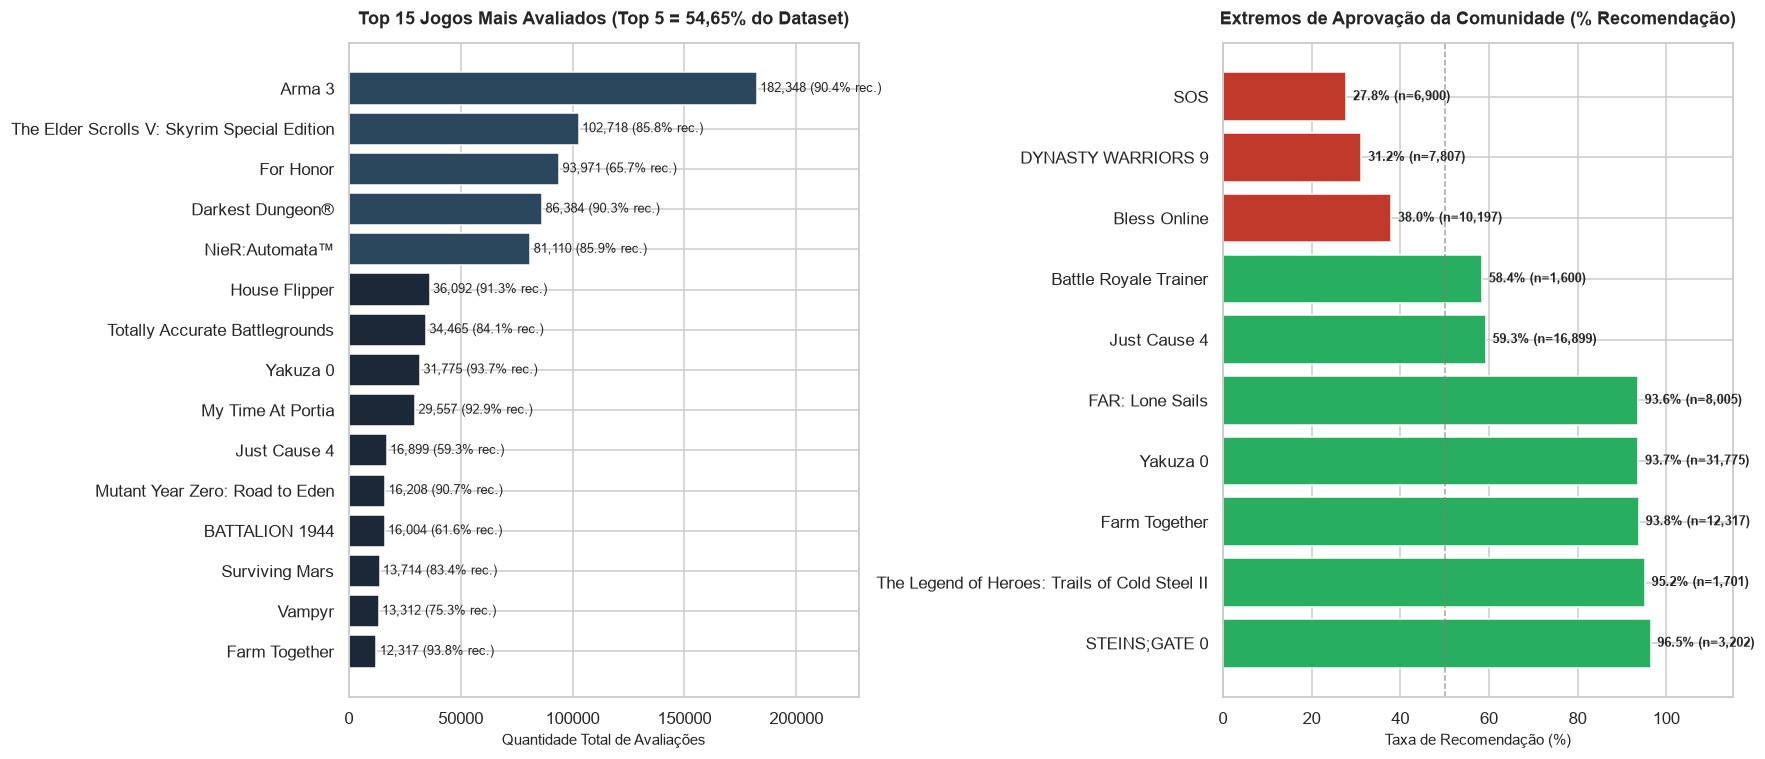

In [40]:
# Plota a concentração das top 15 avaliações e os extremos de aprovação dos jogos
game_summary = df.groupby('app_name').agg(
    total_reviews=('review_id', 'count'),
    pct_rec=('recommended', 'mean'),
    helpful_mean=('votes_helpful', 'mean')
).sort_values('total_reviews', ascending=False)

game_summary['share_dataset'] = (game_summary['total_reviews'] / len(df)) * 100
top5_share = game_summary.iloc[:5]['share_dataset'].sum()
print(f'Participação acumulada dos Top 5 jogos: {top5_share:.2f}% de todo o dataset')

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Subplot 1: Top 15 Jogos Mais Avaliados
top15 = game_summary.head(15).iloc[::-1]
bar_colors = ['#1b2838' if i < 10 else '#2a475e' for i in range(15)]
axes[0].barh(top15.index, top15['total_reviews'], color=bar_colors)
axes[0].set_title('Top 15 Jogos Mais Avaliados (Top 5 = 54,65% do Dataset)', pad=12)
axes[0].set_xlabel('Quantidade Total de Avaliações')
for i, (val, pct) in enumerate(zip(top15['total_reviews'], top15['pct_rec'])):
    axes[0].text(val + 1500, i, f'{val:,} ({pct*100:.1f}% rec.)', va='center', fontsize=8.5)
axes[0].set_xlim(0, top15['total_reviews'].max() * 1.25)

# Subplot 2: Extremos de Aprovação
extreme_games = pd.concat([
    game_summary.sort_values('pct_rec', ascending=False).head(5),
    game_summary.sort_values('pct_rec', ascending=True).head(5).sort_values('pct_rec', ascending=False)
])
extreme_colors = ['#27ae60' if r >= 0.5 else '#c0392b' for r in extreme_games['pct_rec']]
axes[1].barh(extreme_games.index, extreme_games['pct_rec'] * 100, color=extreme_colors)
axes[1].axvline(50, color='gray', linestyle='--', linewidth=1, alpha=0.7)
axes[1].set_title('Extremos de Aprovação da Comunidade (% Recomendação)', pad=12)
axes[1].set_xlabel('Taxa de Recomendação (%)')
axes[1].set_xlim(0, 115)
for i, (val, n) in enumerate(zip(extreme_games['pct_rec'] * 100, extreme_games['total_reviews'])):
    axes[1].text(val + 1.5, i, f'{val:.1f}% (n={n:,})', va='center', fontsize=8.5, fontweight='bold')

plt.tight_layout()
plt.show()

### 5.2 Dinâmica de Sentimento: Positivas vs Negativas ("A Economia da Insatisfação")
No total, 82,97% das avaliações são positivas (`recommended == True`) e 17,03% são negativas. 
Embora em menor volume, os usuários insatisfeitos exibem um padrão de engajamento substancialmente mais ativo e influente: produzem críticas com o dobro de detalhamento, geram mais engajamento útil e provocam mais debates comunitários.

,n_reviews,pct_has_helpful,median_char_len,median_post_playtime,mean_comments
recommended,,,,,
False,170324,63.33,112.00,1.18,0.55
True,829676,31.63,57.00,13.98,0.13


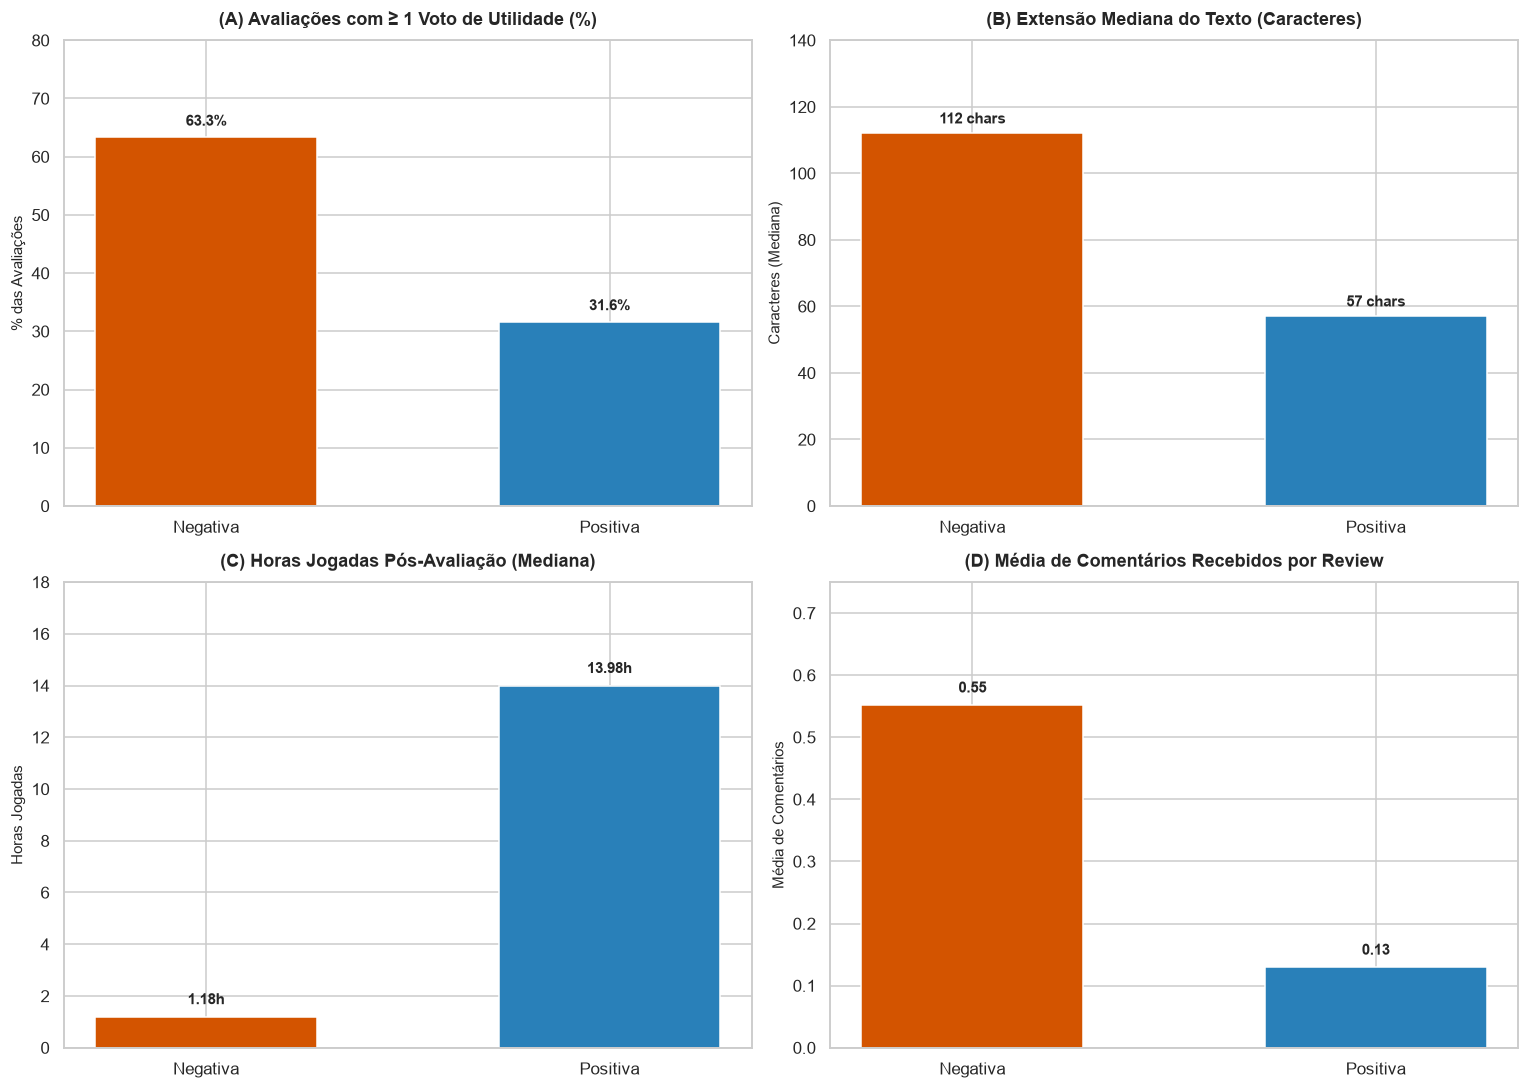

In [41]:
# Gera painel 2x2 comparando métricas comportamentais entre avaliações positivas e negativas
rec_metrics = df.groupby('recommended').agg(
    n_reviews=('review_id', 'count'),
    pct_has_helpful=('votes_helpful', lambda x: (x >= 1).mean() * 100),
    median_char_len=('review_char_len', 'median'),
    median_post_playtime=('post_review_playtime_hrs', 'median'),
    mean_comments=('comment_count', 'mean')
)
display(rec_metrics)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
palette = {'Positiva': '#2980b9', 'Negativa': '#d35400'}
labels = ['Negativa', 'Positiva']

# (A) % com >= 1 voto de utilidade
vals_a = [rec_metrics.loc[False, 'pct_has_helpful'], rec_metrics.loc[True, 'pct_has_helpful']]
bars_a = axes[0, 0].bar(labels, vals_a, color=[palette['Negativa'], palette['Positiva']], width=0.55)
axes[0, 0].set_title('(A) Avaliações com ≥ 1 Voto de Utilidade (%)', pad=10)
axes[0, 0].set_ylabel('% das Avaliações')
axes[0, 0].set_ylim(0, 80)
for bar in bars_a:
    y = bar.get_height()
    axes[0, 0].text(bar.get_x() + bar.get_width()/2, y + 2, f'{y:.1f}%', ha='center', fontweight='bold')

# (B) Mediana de caracteres
vals_b = [rec_metrics.loc[False, 'median_char_len'], rec_metrics.loc[True, 'median_char_len']]
bars_b = axes[0, 1].bar(labels, vals_b, color=[palette['Negativa'], palette['Positiva']], width=0.55)
axes[0, 1].set_title('(B) Extensão Mediana do Texto (Caracteres)', pad=10)
axes[0, 1].set_ylabel('Caracteres (Mediana)')
axes[0, 1].set_ylim(0, 140)
for bar in bars_b:
    y = bar.get_height()
    axes[0, 1].text(bar.get_x() + bar.get_width()/2, y + 3, f'{y:.0f} chars', ha='center', fontweight='bold')

# (C) Mediana de horas pós-review
vals_c = [rec_metrics.loc[False, 'median_post_playtime'], rec_metrics.loc[True, 'median_post_playtime']]
bars_c = axes[1, 0].bar(labels, vals_c, color=[palette['Negativa'], palette['Positiva']], width=0.55)
axes[1, 0].set_title('(C) Horas Jogadas Pós-Avaliação (Mediana)', pad=10)
axes[1, 0].set_ylabel('Horas Jogadas')
axes[1, 0].set_ylim(0, 18)
for bar in bars_c:
    y = bar.get_height()
    axes[1, 0].text(bar.get_x() + bar.get_width()/2, y + 0.5, f'{y:.2f}h', ha='center', fontweight='bold')

# (D) Média de comentários
vals_d = [rec_metrics.loc[False, 'mean_comments'], rec_metrics.loc[True, 'mean_comments']]
bars_d = axes[1, 1].bar(labels, vals_d, color=[palette['Negativa'], palette['Positiva']], width=0.55)
axes[1, 1].set_title('(D) Média de Comentários Recebidos por Review', pad=10)
axes[1, 1].set_ylabel('Média de Comentários')
axes[1, 1].set_ylim(0, 0.75)
for bar in bars_d:
    y = bar.get_height()
    axes[1, 1].text(bar.get_x() + bar.get_width()/2, y + 0.02, f'{y:.2f}', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

### 5.3 A Curva da "Janela de Reembolso" da Steam (Tempo de Jogo vs Recomendação e Utilidade)
A política de reembolso da Steam garante devolução integral sem necessidade de justificativa para jogos com **até 2 horas de execução**.
Essa regra cria uma clivagem comportamental nítida:
1. Jogadores com menos de 2 horas registram aprovação muito mais baixa (49,6% em $<1\text{h}$ e 59,9% entre $1-2\text{h}$);
2. As análises da faixa de reembolso concentram o pico de utilidade da comunidade (~4,77 votos úteis por review), atuando como pareceres de advertência pré-compra;
3. Ultrapassado o marco de 2 horas, a taxa de aprovação salta para 77,4% e avança gradualmente até ultrapassar 93% entre jogadores com centenas de horas.

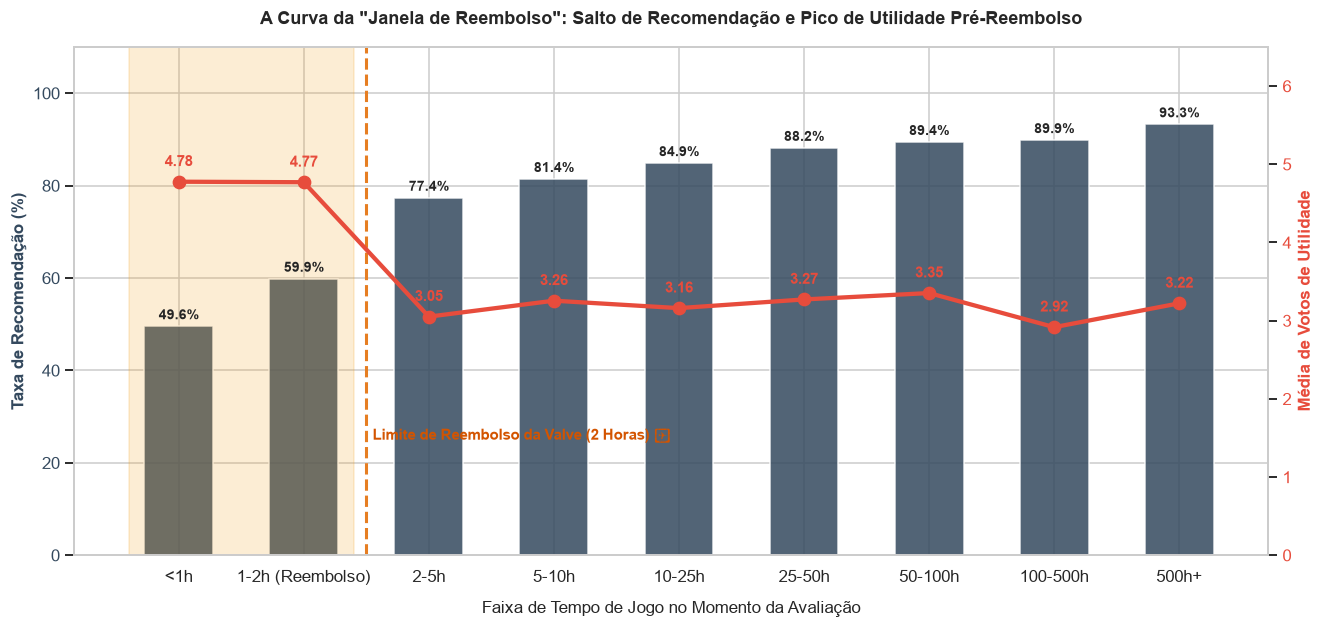

In [42]:
# Segmenta o tempo de jogo em faixas e analisa a taxa de recomendação e votos úteis
playtime_bins = [-np.inf, 1, 2, 5, 10, 25, 50, 100, 500, np.inf]
playtime_labels = ['<1h', '1-2h (Reembolso)', '2-5h', '5-10h', '10-25h', '25-50h', '50-100h', '100-500h', '500h+']
df['playtime_bin'] = pd.cut(df['playtime_at_review_hrs'], bins=playtime_bins, labels=playtime_labels)

refund_stats = df.groupby('playtime_bin', observed=False).agg(
    total_reviews=('review_id', 'count'),
    pct_rec=('recommended', lambda x: x.mean() * 100),
    mean_helpful=('votes_helpful', 'mean')
).reset_index()

fig, ax1 = plt.subplots(figsize=(14, 6))

color_bar = '#34495e'
color_line = '#e74c3c'

bars = ax1.bar(refund_stats['playtime_bin'], refund_stats['pct_rec'], color=color_bar, alpha=0.85, width=0.55, label='Taxa de Recomendação (%)')
ax1.set_ylabel('Taxa de Recomendação (%)', color=color_bar, fontsize=11, fontweight='bold')
ax1.set_ylim(0, 110)
ax1.tick_params(axis='y', labelcolor=color_bar)
ax1.set_xlabel('Faixa de Tempo de Jogo no Momento da Avaliação', fontsize=11, labelpad=10)

for bar in bars:
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, h + 1.5, f'{h:.1f}%', ha='center', fontsize=9, fontweight='bold')

# Eixo secundário: Votos úteis médios
ax2 = ax1.twinx()
line = ax2.plot(refund_stats['playtime_bin'], refund_stats['mean_helpful'], color=color_line, marker='o', linewidth=2.8, markersize=8, label='Média de Votos Úteis')
ax2.set_ylabel('Média de Votos de Utilidade', color=color_line, fontsize=11, fontweight='bold')
ax2.set_ylim(0, 6.5)
ax2.tick_params(axis='y', labelcolor=color_line)
ax2.grid(False)

for i, txt in enumerate(refund_stats['mean_helpful']):
    ax2.annotate(f'{txt:.2f}', (i, txt + 0.2), ha='center', color=color_line, fontweight='bold', fontsize=9.5)

# Destaque visual da janela de reembolso
ax1.axvspan(-0.4, 1.4, color='#f39c12', alpha=0.18)
ax1.axvline(1.5, color='#e67e22', linestyle='--', linewidth=2)
ax1.text(1.55, 25, 'Limite de Reembolso da Valve (2 Horas) ➔', color='#d35400', fontweight='bold', fontsize=10)

plt.title('A Curva da "Janela de Reembolso": Salto de Recomendação e Pico de Utilidade Pré-Reembolso', pad=15)
plt.show()

### 5.4 Impacto da Modalidade de Compra, Early Access e Edição de Reviews
Avaliamos quatro características da aquisição e elaboração das avaliações:
- `steam_purchase`: aquisição direta na loja da Steam versus chaves de ativação externas (83,8% vs 81,2%);
- `received_for_free`: jogo recebido gratuitamente (78,7% vs 83,2%);
- `written_during_early_access`: avaliações durante Acesso Antecipado sofrem severa penalidade de 14,0 pontos percentuais (69,8% vs 83,8%);
- `is_edited`: revisões editadas recebem 3,3x mais votos de utilidade (8,43 vs 2,56) e possuem textos 4x mais extensos.

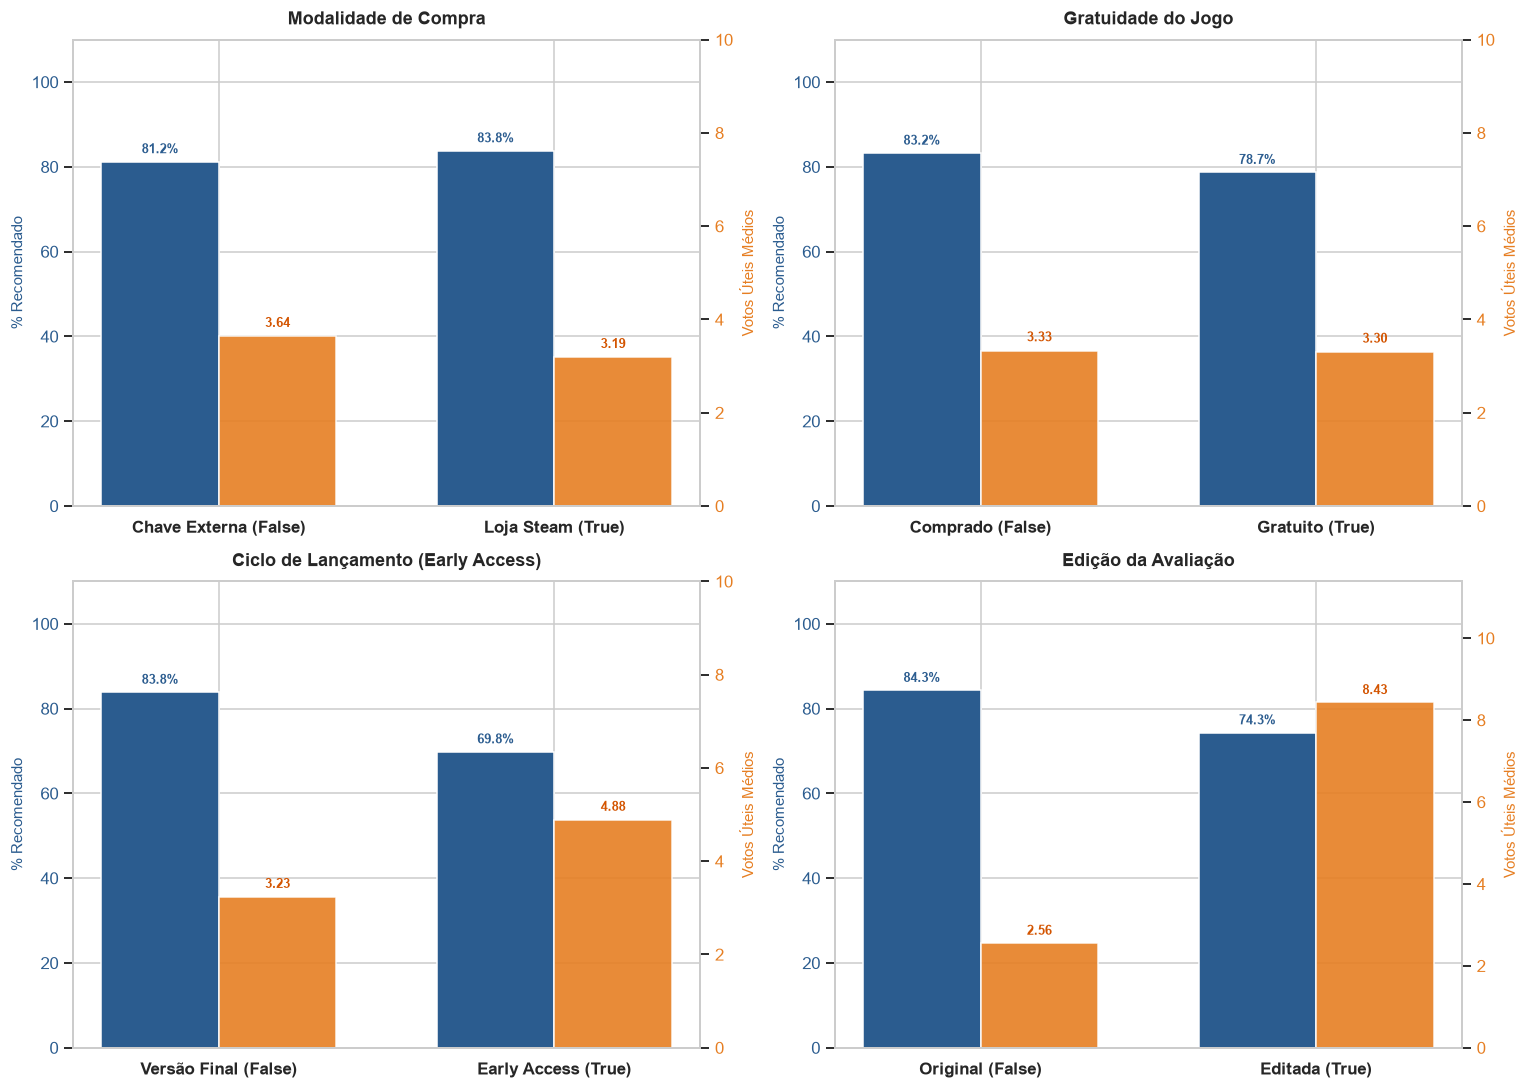

In [43]:
# Compara métricas de recomendação e utilidade por modalidade de aquisição e status do review
factors = [
    ('steam_purchase', 'Modalidade de Compra', ['Chave Externa (False)', 'Loja Steam (True)']),
    ('received_for_free', 'Gratuidade do Jogo', ['Comprado (False)', 'Gratuito (True)']),
    ('written_during_early_access', 'Ciclo de Lançamento (Early Access)', ['Versão Final (False)', 'Early Access (True)']),
    ('is_edited', 'Edição da Avaliação', ['Original (False)', 'Editada (True)'])
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (col, title, xlabels) in zip(axes.flat, factors):
    grp = df.groupby(col).agg(
        pct_rec=('recommended', lambda x: x.mean() * 100),
        helpful=('votes_helpful', 'mean'),
        count=('review_id', 'count')
    )
    
    x = np.arange(2)
    width = 0.35
    
    # Eixo primário: % recomendação
    b1 = ax.bar(x - width/2, grp['pct_rec'], width, label='% Recomendado', color='#2b5c8f')
    ax.set_ylabel('% Recomendado', color='#2b5c8f')
    ax.set_ylim(0, 110)
    ax.tick_params(axis='y', labelcolor='#2b5c8f')
    ax.set_xticks(x)
    ax.set_xticklabels(xlabels, fontweight='bold')
    ax.set_title(title, pad=10)
    
    for bar in b1:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 2, f'{h:.1f}%', ha='center', fontsize=8.5, fontweight='bold', color='#2b5c8f')
        
    # Eixo secundário: votos úteis
    ax_twin = ax.twinx()
    b2 = ax_twin.bar(x + width/2, grp['helpful'], width, label='Votos Úteis', color='#e67e22', alpha=0.9)
    ax_twin.set_ylabel('Votos Úteis Médios', color='#e67e22')
    ax_twin.set_ylim(0, max(grp['helpful'].max() * 1.35, 10))
    ax_twin.tick_params(axis='y', labelcolor='#e67e22')
    ax_twin.grid(False)
    
    for bar in b2:
        h = bar.get_height()
        ax_twin.text(bar.get_x() + bar.get_width()/2, h + 0.2, f'{h:.2f}', ha='center', fontsize=8.5, fontweight='bold', color='#d35400')

plt.tight_layout()
plt.show()

### 5.5 O Paradoxo do Crítico Veterano e Panorama por Idioma
Ao agrupar os autores por experiência (`author.num_reviews`), constata-se um padrão claro: usuários com mais reviews tornam-se sistematicamente mais rigorosos (a aprovação cai de 84,9% para 76,8%), mas suas análises conquistam autoridade crescente na plataforma (os votos úteis médios sobem de 2,14 para 7,09).

Entre os principais idiomas, o Inglês predomina (49,1%), enquanto o Chinês Simplificado (15,1%) destaca-se por uma comunidade particularmente crítica e engajada (76,6% de aprovação e 6,15 votos úteis médios). O Português Brasileiro (2,8%) registra elevado entusiasmo (88,2% de aprovação).

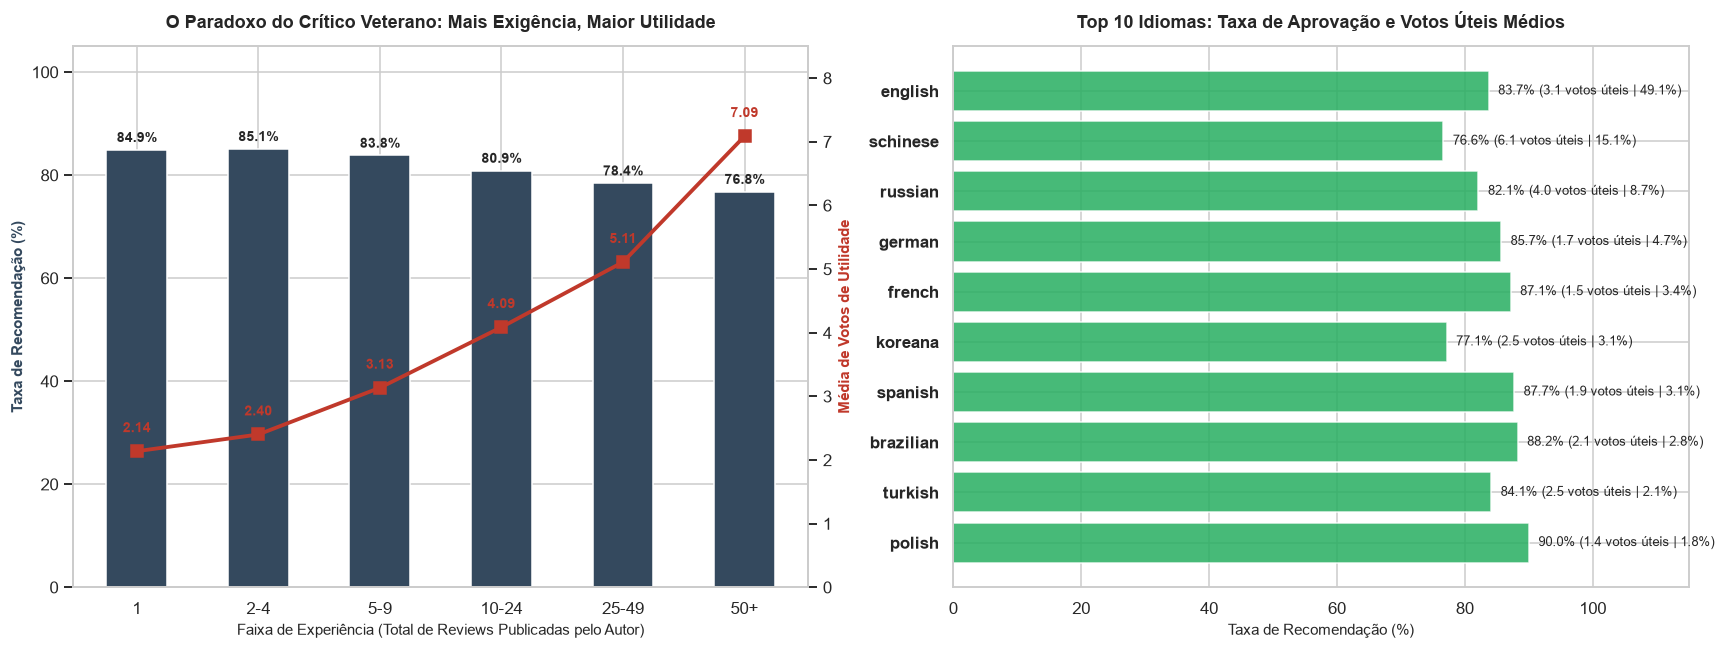

In [44]:
# Avalia a evolução do rigor crítico por faixa de experiência e o perfil dos principais idiomas
exp_bins = [0, 1, 4, 9, 24, 49, np.inf]
exp_labels = ['1', '2-4', '5-9', '10-24', '25-49', '50+']
df['exp_tier'] = pd.cut(df['author.num_reviews'], bins=exp_bins, labels=exp_labels)

exp_stats = df.groupby('exp_tier', observed=False).agg(
    total_reviews=('review_id', 'count'),
    pct_rec=('recommended', lambda x: x.mean() * 100),
    mean_helpful=('votes_helpful', 'mean')
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Paradoxo do Crítico Veterano
ax_exp1 = axes[0]
bars_exp = ax_exp1.bar(exp_stats['exp_tier'], exp_stats['pct_rec'], color='#34495e', width=0.5, label='% Recomendação')
ax_exp1.set_ylabel('Taxa de Recomendação (%)', color='#34495e', fontweight='bold')
ax_exp1.set_ylim(0, 105)
ax_exp1.set_xlabel('Faixa de Experiência (Total de Reviews Publicadas pelo Autor)')
ax_exp1.set_title('O Paradoxo do Crítico Veterano: Mais Exigência, Maior Utilidade', pad=12)

for bar in bars_exp:
    h = bar.get_height()
    ax_exp1.text(bar.get_x() + bar.get_width()/2, h + 1.5, f'{h:.1f}%', ha='center', fontsize=9, fontweight='bold')

ax_exp2 = ax_exp1.twinx()
ax_exp2.plot(exp_stats['exp_tier'], exp_stats['mean_helpful'], color='#c0392b', marker='s', linewidth=2.5, markersize=8)
ax_exp2.set_ylabel('Média de Votos de Utilidade', color='#c0392b', fontweight='bold')
ax_exp2.set_ylim(0, 8.5)
ax_exp2.grid(False)

for i, txt in enumerate(exp_stats['mean_helpful']):
    ax_exp2.annotate(f'{txt:.2f}', (i, txt + 0.3), ha='center', color='#c0392b', fontweight='bold', fontsize=9)

# Subplot 2: Top 10 Idiomas
top_langs = df.groupby('language').agg(
    count=('review_id', 'count'),
    pct_rec=('recommended', lambda x: x.mean() * 100),
    helpful=('votes_helpful', 'mean')
).sort_values('count', ascending=True).tail(10)

y_pos = np.arange(len(top_langs))
axes[1].barh(y_pos, top_langs['pct_rec'], color='#27ae60', alpha=0.85)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(top_langs.index, fontweight='bold')
axes[1].set_xlabel('Taxa de Recomendação (%)')
axes[1].set_xlim(0, 115)
axes[1].set_title('Top 10 Idiomas: Taxa de Aprovação e Votos Úteis Médios', pad=12)

for i, (pct, count, hlp) in enumerate(zip(top_langs['pct_rec'], top_langs['count'], top_langs['helpful'])):
    axes[1].text(pct + 1.5, i, f'{pct:.1f}% ({hlp:.1f} votos úteis | {(count/len(df))*100:.1f}%)', va='center', fontsize=8.5)

plt.tight_layout()
plt.show()

### 5.6 Sazonalidade e Evolução Temporal das Avaliações
Analisamos a evolução mensal do volume e da satisfação entre 2017 e 2020. 
Observam-se picos de atividade expressivos coincidentes com os principais eventos promocionais da Steam:
- **Steam Summer Sale**: concentrada entre junho e julho;
- **Steam Autumn & Winter Sale**: concentradas entre novembro e dezembro.

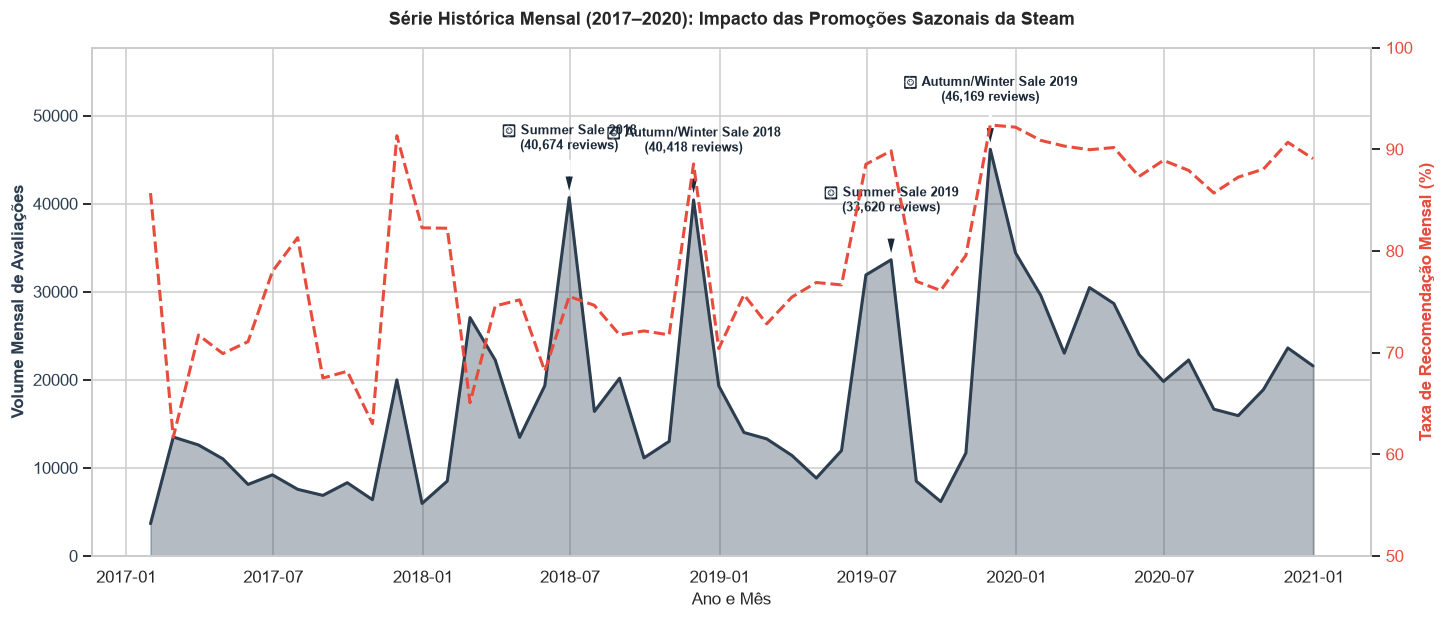

In [45]:
# Agrupa e plota a evolução mensal do volume de reviews e taxa de recomendação
df_time = df[(df['date_created'] >= '2017-01-01') & (df['date_created'] <= '2020-12-31')].copy()
monthly_ts = df_time.set_index('date_created').resample('ME').agg(
    volume=('review_id', 'count'),
    pct_rec=('recommended', lambda x: x.mean() * 100)
).reset_index()

fig, ax1 = plt.subplots(figsize=(15, 6))

color_vol = '#2c3e50'
color_rate = '#2980b9'

ax1.fill_between(monthly_ts['date_created'], monthly_ts['volume'], color=color_vol, alpha=0.35, label='Volume Mensal de Reviews')
ax1.plot(monthly_ts['date_created'], monthly_ts['volume'], color=color_vol, linewidth=2)
ax1.set_ylabel('Volume Mensal de Avaliações', color=color_vol, fontsize=11, fontweight='bold')
ax1.set_ylim(0, monthly_ts['volume'].max() * 1.25)
ax1.tick_params(axis='y', labelcolor=color_vol)
ax1.set_xlabel('Ano e Mês', fontsize=11)

# Eixo secundário: Taxa de recomendação
ax2 = ax1.twinx()
ax2.plot(monthly_ts['date_created'], monthly_ts['pct_rec'], color='#e74c3c', linestyle='--', linewidth=2, label='Taxa de Recomendação (%)')
ax2.set_ylabel('Taxa de Recomendação Mensal (%)', color='#e74c3c', fontsize=11, fontweight='bold')
ax2.set_ylim(50, 100)
ax2.tick_params(axis='y', labelcolor='#e74c3c')
ax2.grid(False)

# Anotações dos picos de vendas
sales_annotations = [
    (pd.Timestamp('2018-06-30', tz='UTC'), 40674, 'Summer Sale 2018'),
    (pd.Timestamp('2018-11-30', tz='UTC'), 40418, 'Autumn/Winter Sale 2018'),
    (pd.Timestamp('2019-07-31', tz='UTC'), 33620, 'Summer Sale 2019'),
    (pd.Timestamp('2019-11-30', tz='UTC'), 46169, 'Autumn/Winter Sale 2019')
]

for dt, vol, label in sales_annotations:
    ax1.annotate(f'★ {label}\n({vol:,} reviews)', 
                 xy=(dt, vol), 
                 xytext=(dt, vol + 5500),
                 ha='center',
                 fontsize=8.5,
                 fontweight='bold',
                 color='#1b2838',
                 arrowprops=dict(facecolor='#1b2838', shrink=0.08, width=1, headwidth=6))

plt.title('Série Histórica Mensal (2017–2020): Impacto das Promoções Sazonais da Steam', pad=15)
plt.show()

## 6. Síntese das Descobertas e Próximos Passos

### 6.1 Síntese da Arquitetura e Higienização
1. **Integridade Relacional Perfeita**: As quatro partições (`review_info`, `game_info`, `author_info`, `purchase_info`) compartilham exatamente o mesmo conjunto de 1.000.000 de `review_id`, compondo uma partição vertical estrita 1:1 sem registros órfãos.
2. **Correção de Underflow de 32 Bits**: Identificação e mitigação do bug em `votes_funny`, onde 49 registros com valores $\ge 4.294.967.292$ (valores lógicos de $-1$ a $-4$) foram normalizados para 0.
3. **Controle de Spams Textuais**: Detecção de dois textos aberrantes com 9,64M e 4,97M de caracteres que violam o limite oficial de 8.000 caracteres da Steam, estabelecendo a necessidade de truncamento preventivo para modelos de NLP.
4. **Padronização de Unidades**: Conversão unificada dos tempos de jogo em horas e geração do indicador de reviews editadas (`is_edited`), abrangendo 13,11% da base.

### 6.2 Principais Descobertas Comportamentais
1. **A Economia da Insatisfação**: Avaliações negativas (17,03%) recebem o dobro de votos de utilidade (63,3% vs 31,6%), possuem o dobro do comprimento mediano (112 vs 57 caracteres) e geram 4,2x mais comentários do que análises positivas.
2. **A Janela de Reembolso como Divisor de Águas**: Análises produzidas antes de 2 horas de jogo registram forte insatisfação (~49% a 60% de aprovação) e concentram o pico de utilidade da comunidade (~4,77 votos úteis). Após 2 horas, a taxa de aprovação salta para mais de 77%, atingindo 93% entre jogadores com centenas de horas.
3. **Penalidade de Early Access**: Avaliações publicadas durante Acesso Antecipado sofrem uma penalidade de 14,0 pontos percentuais de aprovação frente a lançamentos finais (69,8% vs 83,8%).
4. **O Paradoxo do Crítico Veterano**: Usuários com maior histórico de avaliações são progressivamente mais exigentes (aprovação cai de 84,9% para 76,8%), porém recebem maior prestígio comunitário (utilidade sobe de 2,14 para 7,09 votos úteis).
5. **Impacto de Atualizações no Review**: Avaliações editadas recebem 3,3x mais votos de utilidade e são 4x mais extensas em média do que avaliações originais não alteradas.

### 6.3 Recomendações para Modelagem Preditiva e NLP
- **Modelos de Sentimento e Classificação**: Truncar os textos no limite de 8.000 caracteres para preservar a integridade de memória e considerar a forte assimetria de tamanho entre avaliações positivas e negativas.
- **Predição de Utilidade (Helpfulness)**: Utilizar features fortes descobertas na análise, como tempo de jogo no momento da avaliação, status de edição, modalidade de compra e histórico do autor (`author.num_reviews`).
- **Monitoramento de Sazonalidade**: Ajustar modelos temporais para incorporar os surtos de volume nas janelas sazonais de promoções da Steam (junho/julho e novembro/dezembro).